In [1]:

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from datasets import load_dataset

In [2]:
emotion_dataset = load_dataset('dair-ai/emotion')

train_text = emotion_dataset['train']['text']
train_label = emotion_dataset['train']['label']

test_text = emotion_dataset['test']['text']
test_label = emotion_dataset['test']['label']

README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

split/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

split/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127kB            

split/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  129kB            

split/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

In [3]:
label_names = emotion_dataset['train'].features['label'].names


In [4]:
label_names

['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']

In [5]:
df_train = pd.DataFrame(
    {
        'text' : train_text,
        'label' : [label_names[i]for i in train_label]
    }
)

df_test = pd.DataFrame(
    {
        'text' : test_text,
        'label' : [label_names[i]for i in test_label]
    }
)

In [6]:
df_train.head()

,text,label
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger


In [7]:
df_test.isnull().sum()

,0
text,0
label,0


In [8]:
df_train['label'].value_counts().index

Index(['joy', 'sadness', 'anger', 'fear', 'love', 'surprise'], dtype='object', name='label')

<Axes: xlabel='label', ylabel='count'>

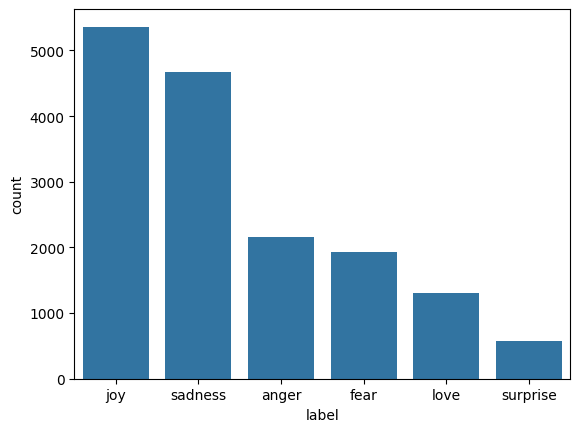

In [9]:
sns.countplot(x= 'label',  data= df_train,  order=df_train['label'].value_counts().index)

In [10]:
df_train

,text,label
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger
...,...,...
15995,i just had a very brief time in the beanbag an...,sadness
15996,i am now turning and i feel pathetic that i am...,sadness
15997,i feel strong and good overall,joy
15998,i feel like this was such a rude comment and i...,anger


### Using NLP


In [11]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
max_words= 10000

tokenizer = Tokenizer(num_words= max_words, oov_token = '<unk>')
tokenizer.fit_on_texts(df_train['text'])

train_sequences = tokenizer.texts_to_sequences(df_train['text'])
test_sequences = tokenizer.texts_to_sequences(df_test['text'])

padded_train_sequences = pad_sequences(train_sequences,padding ='post',truncating='post')
padded_test_sequences = pad_sequences(test_sequences, padding ='post',truncating='post')

train_labels = np.array(train_label)
test_labels = np.array(test_label)

num_classes = np.unique(train_labels)
num_classes

print(f"vocabulary Size: {len(tokenizer.word_index)}")
print(f"Max Sequence Length: {padded_train_sequences.shape[1]}")

vocabulary Size: 15213
Max Sequence Length: 66


In [12]:
from sklearn.utils import class_weight

class_weights = class_weight.compute_class_weight(
    class_weight = 'balanced',
    classes      = np.unique(train_labels),
    y            = train_labels
)

class_weight_dict = dict(enumerate(class_weights))

In [13]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

In [14]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Embedding, Dense, Dropout
from tensorflow.keras.preprocessing.sequence import pad_sequences

padded_train_sequences_fixed = pad_sequences(train_sequences, maxlen=50, padding='post', truncating='post')
padded_test_sequences_fixed = pad_sequences(test_sequences, maxlen=50, padding='post', truncating='post')

rnn_model = Sequential([
    Embedding(input_dim=max_words, output_dim=128),
    SimpleRNN(units=128, return_sequences=False), # Changed to False for sequence classification
    Dropout(0.5),
    Dense(units=len(num_classes), activation='softmax')
])

rnn_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# 4. Train the model with the correctly sized data
rnn_model.fit(
    padded_train_sequences_fixed,
    train_labels,
    validation_data=(padded_test_sequences_fixed, test_labels),
    epochs=20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

# 5. Evaluate
rnn_loss, rnn_accuracy = rnn_model.evaluate(padded_test_sequences_fixed, test_labels)
print(f"RNN Loss: {rnn_loss}")
print(f"RNN Accuracy: {rnn_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 19s 34ms/step - accuracy: 0.1704 - loss: 1.8101 - val_accuracy: 0.2515 - val_loss: 1.7736
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 21s 35ms/step - accuracy: 0.1756 - loss: 1.7885 - val_accuracy: 0.0885 - val_loss: 1.8164
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 16s 33ms/step - accuracy: 0.1774 - loss: 1.8540 - val_accuracy: 0.0440 - val_loss: 1.8377
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 16s 33ms/step - accuracy: 0.1448 - loss: 1.8990 - val_accuracy: 0.2435 - val_loss: 1.7214
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 22s 35ms/step - accuracy: 0.1428 - loss: 1.8328 - val_accuracy: 0.1490 - val_loss: 1.8245
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 17s 35ms/step - accuracy: 0.1405 - loss: 1.8174 - val_accuracy: 0.1535 - val_loss: 1.8148
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 17s 33ms/step - accuracy: 0.1348 - loss: 1.8120 - val_accuracy: 0.1350 - val_loss: 1.8121
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.2435 - loss: 1.7214
RNN Loss: 1.72135

## Using LSTM

In [15]:
from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import SimpleRNN, Embedding, Dense, Dropout, LSTM, GRU


lstm_model = Sequential([
    Embedding(input_dim = max_words, output_dim = 128 , input_length = 50),
    LSTM(units=128, return_sequences=True),
    Dropout(0.5),
    LSTM(units=64),
    Dropout(0.5),
    Dense(units=len(num_classes), activation='softmax') #Output Layer
])

lstm_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [16]:
lstm_model.fit(
    padded_train_sequences_fixed,
    train_labels,
    validation_data=(padded_test_sequences_fixed, test_labels),
    epochs = 20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

lstm_loss, lstm_accuracy = lstm_model.evaluate(padded_test_sequences_fixed, test_labels)
print(f"LSTM Loss: {lstm_loss}")
print(f"LSTM Accuracy: {lstm_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 68s 129ms/step - accuracy: 0.1504 - loss: 1.7958 - val_accuracy: 0.2790 - val_loss: 1.7866
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 65s 131ms/step - accuracy: 0.1577 - loss: 1.7933 - val_accuracy: 0.0395 - val_loss: 1.8097
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 65s 130ms/step - accuracy: 0.1538 - loss: 1.8008 - val_accuracy: 0.1120 - val_loss: 1.7935
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 41ms/step - accuracy: 0.2790 - loss: 1.7866
LSTM Loss: 1.7866311073303223
LSTM Accuracy: 0.27900001406669617


In [17]:
gru_model = Sequential([
    Embedding(input_dim = max_words, output_dim = 128 , input_length = 50),
    GRU(units=128, return_sequences=True),
    Dropout(0.5),
    GRU(units=64),
    Dropout(0.5),
    Dense(units=len(num_classes), activation='softmax') #Output Layer
])

gru_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

gru_model.fit(
    padded_train_sequences_fixed,
    train_labels,
    validation_data=(padded_test_sequences_fixed, test_labels),
    epochs = 20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

gru_loss, gru_accuracy = gru_model.evaluate(padded_test_sequences_fixed, test_labels)
print(f"GRU Loss: {gru_loss}")
print(f"GRU Accuracy: {gru_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 59s 112ms/step - accuracy: 0.1476 - loss: 1.7965 - val_accuracy: 0.1420 - val_loss: 1.7733
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 56s 112ms/step - accuracy: 0.1336 - loss: 1.7953 - val_accuracy: 0.3500 - val_loss: 1.7700
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 55s 110ms/step - accuracy: 0.1616 - loss: 1.7944 - val_accuracy: 0.3460 - val_loss: 1.7870
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.1420 - loss: 1.7733
GRU Loss: 1.7732914686203003
GRU Accuracy: 0.1420000046491623


In [19]:
result_df = pd.DataFrame({
    'Model' : ['RNN', 'LSTM', 'GRU'],
    'Test Loss': [rnn_loss, lstm_loss, gru_loss],
    'Test Accuracy': [rnn_accuracy, lstm_accuracy, gru_accuracy]
    }).sort_values(by='Test Accuracy',ascending=False)
result_df


,Model,Test Loss,Test Accuracy
1,LSTM,1.786631,0.2790
0,RNN,1.721357,0.2435
2,GRU,1.773291,0.1420


In [24]:
from tensorflow.keras.layers import Bidirectional

BIGRU = Sequential([
    Embedding(input_dim = max_words, output_dim = 300 , input_length = 50),
    Bidirectional(GRU(128, return_sequences=True)),
    Dropout(0.5),
    Bidirectional(GRU(64)),
    Dropout(0.5),
    Dense(units=len(num_classes), activation='softmax') #Output Layer
])

BIGRU.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

BIGRU.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_7 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_8 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_9 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [26]:
BIGRU.fit(
    padded_train_sequences_fixed,
    train_labels,
    validation_data=(padded_test_sequences_fixed, test_labels),
    epochs = 20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 164s 327ms/step - accuracy: 0.5862 - loss: 1.0329 - val_accuracy: 0.8900 - val_loss: 0.3355
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 159s 318ms/step - accuracy: 0.9184 - loss: 0.2416 - val_accuracy: 0.9130 - val_loss: 0.2392
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 162s 324ms/step - accuracy: 0.9437 - loss: 0.1591 - val_accuracy: 0.9170 - val_loss: 0.2423
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 197s 314ms/step - accuracy: 0.9594 - loss: 0.1094 - val_accuracy: 0.9190 - val_loss: 0.2551
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 155s 310ms/step - accuracy: 0.9676 - loss: 0.0868 - val_accuracy: 0.9190 - val_loss: 0.2370
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 158s 317ms/step - accuracy: 0.9741 - loss: 0.0698 - val_accuracy: 0.9240 - val_loss: 0.2686
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 157s 315ms/step - accuracy: 0.9794 - loss: 0.0561 - val_accuracy: 0.9160 - val_loss: 0.2899
Epoch 8/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 157s 313ms/step - accuracy: 0.9827 -

In [33]:
BIGRU_loss, BIGRU_accuracy = BIGRU.evaluate(padded_test_sequences_fixed, test_labels)
print(f"BIGRU Loss: {BIGRU_loss}")
print(f"BIGRU Accuracy: {BIGRU_accuracy}")

63/63 ━━━━━━━━━━━━━━━━━━━━ 6s 91ms/step - accuracy: 0.9190 - loss: 0.2370
BIGRU Loss: 0.23701466619968414
BIGRU Accuracy: 0.9190000295639038


63/63 ━━━━━━━━━━━━━━━━━━━━ 11s 150ms/step


<Axes: >

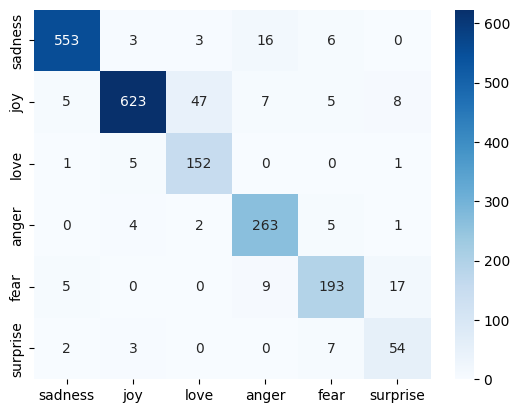

In [36]:
from sklearn.metrics import confusion_matrix

BIGRU_predictions = np.argmax(BIGRU.predict(padded_test_sequences_fixed),axis=1)

sns.heatmap(confusion_matrix(test_label, BIGRU_predictions),annot=True, fmt='d', cmap='Blues', xticklabels=label_names, yticklabels=label_names)


In [40]:
sample_texts = [
    "I can't believe how happy I am right now, this is amazing!",
    "I feel so alone and hopeless today.",
    "I am furious that they cancelled the trip at the last minute.",
    "I feel terrified when walking down dark alleyways alone.",
    "I was shocked and completely surprised by the unexpected gift!"
]

sample_sequences = tokenizer.texts_to_sequences(sample_texts)
sample_padded_sequences = pad_sequences(sample_sequences, maxlen=50, padding='post', truncating='post')

sample_predictions = np.argmax(BIGRU.predict(sample_padded_sequences), axis=1)

for i in range(len(sample_texts)):
  print(f'Text: {sample_texts[i]}\nPredicted Emotion: {label_names[sample_predictions[i]]}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
Text: I can't believe how happy I am right now, this is amazing!
Predicted Emotion: joy
Text: I feel so alone and hopeless today.
Predicted Emotion: sadness
Text: I am furious that they cancelled the trip at the last minute.
Predicted Emotion: anger
Text: I feel terrified when walking down dark alleyways alone.
Predicted Emotion: fear
Text: I was shocked and completely surprised by the unexpected gift!
Predicted Emotion: surprise


In [43]:

import os
import pickle

model_dir = 'Artifacts'
os.makedirs(model_dir, exist_ok=True) #yeh folder hai jiske andar sari exported file aane wali hai

BIGRU.save(os.path.join(model_dir, 'BIGRU_Modle.keras'))

#Save the tokenizer model
with open(os.path.join(model_dir, 'tokenizer.pkl'), 'wb') as file:
  pickle.dump(tokenizer, file)

In [1]:
import pickle
from tensorflow.keras.preprocessing.text import Tokenizer

tokenizer = Tokenizer(num_words=10000, oov_token="<OOV>")
tokenizer.fit_on_texts(train_texts)

with open("artifacts/tokenizer.pkl", "wb") as handle:
    pickle.dump(tokenizer, handle)


ModuleNotFoundError: No module named 'tensorflow'